<a href="https://colab.research.google.com/github/Anmol7209/PythonProject2/blob/main/image_detection_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Detection Project

This project implements an object detection pipeline using a pre-trained **SSD MobileNet V2** model from **TensorFlow Hub**. It loads an image from a URL, detects objects, and visualizes the results by drawing bounding boxes with class labels and confidence scores.

In [5]:
import os
import cv2
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import requests
from io import BytesIO

print("TensorFlow version:", tf.__version__)
print("TensorFlow Hub version:", hub.__version__)

TensorFlow version: 2.21.0
TensorFlow Hub version: 0.16.1


### Load Model and Utility Functions

We will load the **SSD MobileNet V2** model from TensorFlow Hub and set up helper functions to fetch images from URLs and paint bounding boxes on them.

In [6]:
# Load SSD MobileNet V2 from TensorFlow Hub
detector_url = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
print("Loading model from TF Hub...")
detector = hub.load(detector_url)
print("Model loaded successfully!")

def load_image_from_url(url):
    """Downloads an image and returns it as a numpy array."""
    response = requests.get(url)
    image = Image.open(BytesIO(response.content))
    # Convert to RGB if needed
    if image.mode != "RGB":
        image = image.convert("RGB")
    return np.array(image)

def draw_bounding_boxes(image_np, boxes, class_names, scores, max_boxes=10, min_score=0.4):
    """Draws bounding boxes and labels on the image."""
    image_pil = Image.fromarray(np.uint8(image_np)).convert("RGB")
    draw = ImageDraw.Draw(image_pil)
    im_width, im_height = image_pil.size

    for i in range(min(boxes.shape[0], max_boxes)):
        if scores[i] >= min_score:
            ymin, xmin, ymax, xmax = boxes[i]
            (left, right, top, bottom) = (xmin * im_width, xmax * im_width,
                                          ymin * im_height, ymax * im_height)

            # Draw bounding box
            draw.line([(left, top), (left, bottom), (right, bottom), (right, top), (left, top)],
                      width=4, fill="red")

            # Draw label and score
            label = f"{class_names[i]}: {int(scores[i] * 100)}%"
            draw.text((left + 5, top + 5), label, fill="red")

    return np.array(image_pil)

Loading model from TF Hub...
Model loaded successfully!


### Define Coco Class Labels

Since SSD MobileNet V2 is trained on the COCO dataset, we map the output class IDs to the actual category labels.

In [8]:
# COCO labels mapping (standard 90 classes used by SSD MobileNet)
COCO_CLASSES = {
    1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 5: 'airplane',
    6: 'bus', 7: 'train', 8: 'truck', 9: 'boat', 10: 'traffic light',
    11: 'fire hydrant', 13: 'stop sign', 14: 'parking meter', 15: 'bench',
    16: 'bird', 17: 'cat', 18: 'dog', 19: 'horse', 20: 'sheep', 21: 'cow',
    22: 'elephant', 23: 'bear', 24: 'zebra', 25: 'giraffe', 27: 'backpack',
    28: 'umbrella', 31: 'handbag', 32: 'tie', 33: 'suitcase', 34: 'frisbee',
    35: 'skis', 36: 'snowboard', 37: 'sports ball', 38: 'kite', 39: 'baseball bat',
    40: 'baseball glove', 41: 'skateboard', 42: 'surfboard', 43: 'tennis racket',
    44: 'bottle', 46: 'wine glass', 47: 'cup', 48: 'fork', 49: 'knife',
    50: 'spoon', 51: 'bowl', 52: 'banana', 53: 'apple', 54: 'sandwich',
    55: 'orange', 56: 'broccoli', 57: 'carrot', 58: 'hot dog', 59: 'pizza',
    60: 'donut', 61: 'cake', 62: 'chair', 63: 'couch', 64: 'potted plant',
    65: 'bed', 67: 'dining table', 70: 'toilet', 72: 'tv', 73: 'laptop',
    74: 'mouse', 75: 'remote', 76: 'keyboard', 77: 'cell phone', 78: 'microwave',
    79: 'oven', 80: 'toaster', 81: 'sink', 82: 'refrigerator', 84: 'book',
    85: 'clock', 86: 'vase', 87: 'scissors', 88: 'teddy bear', 89: 'hair drier',
    90: 'toothbrush'
}

### Run Detection

Provide an image URL to test the model.

Running detection...


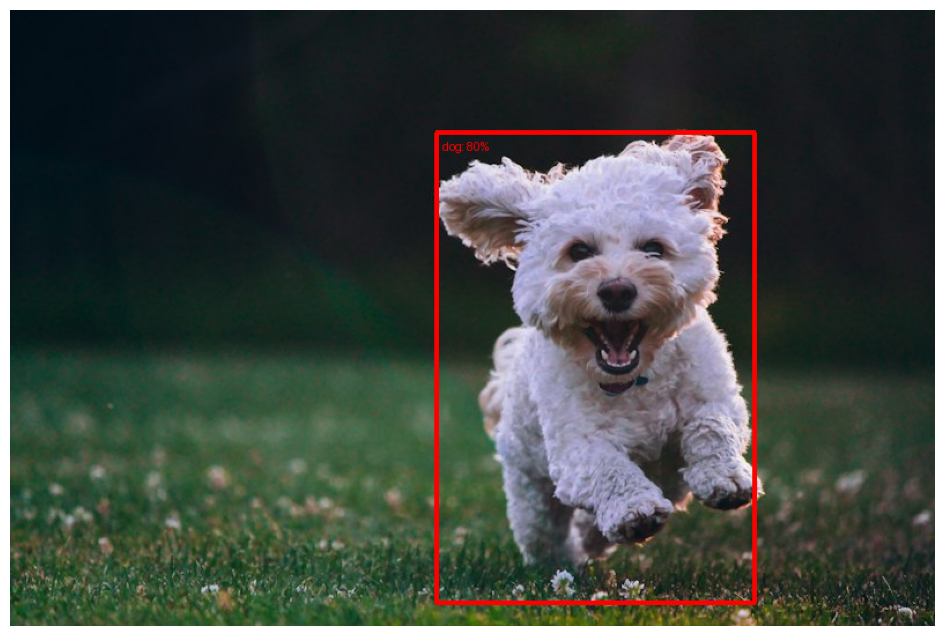

In [10]:
# Test image URL (you can replace this with any image link)
image_url = "https://images.unsplash.com/photo-1534361960057-19889db9621e?auto=format&fit=crop&w=800&q=80"

try:
    # Load and preprocess image
    image_np = load_image_from_url(image_url)
    input_tensor = tf.convert_to_tensor(image_np)
    input_tensor = input_tensor[tf.newaxis, ...]

    # Run prediction
    print("Running detection...")
    detections = detector(input_tensor)

    # Process results
    detection_boxes = detections['detection_boxes'][0].numpy()
    detection_classes = detections['detection_classes'][0].numpy().astype(np.int32)
    detection_scores = detections['detection_scores'][0].numpy()

    # Map IDs to actual names
    class_names = [COCO_CLASSES.get(cid, f'unknown ({cid})') for cid in detection_classes]

    # Draw and display results
    result_image = draw_bounding_boxes(image_np, detection_boxes, class_names, detection_scores, min_score=0.5)

    plt.figure(figsize=(12, 8))
    plt.imshow(result_image)
    plt.axis('off')
    plt.show()
except Exception as e:
    print("An error occurred:", e)

### Provide Input by Uploading Your Own Image (Upload Local Image)

Run the cell below. An **Upload** button will appear. Click on it to select and upload any image from your computer or phone. This code will use that image as input, run object detection, and show the detected objects in the output.

Please click on the button below to upload your image file:


Saving josh-berquist-_4sWbzH5fp8-unsplash.jpg to josh-berquist-_4sWbzH5fp8-unsplash (1).jpg
Running object detection on 'josh-berquist-_4sWbzH5fp8-unsplash (1).jpg'...


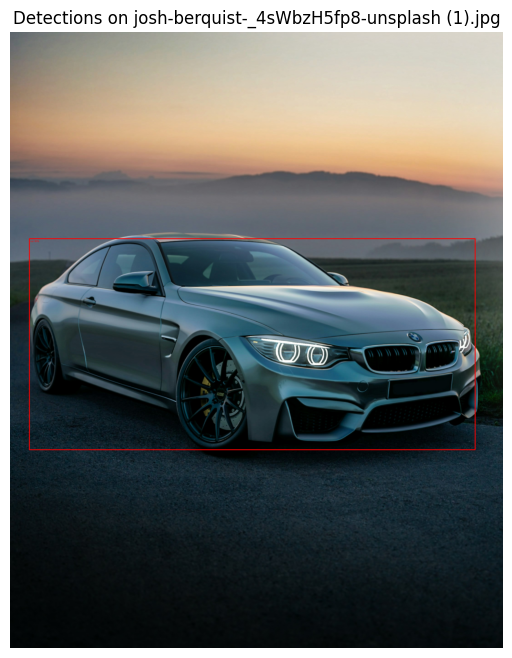

In [12]:
from google.colab import files
import io

print("Please click on the button below to upload your image file:")
uploaded = files.upload()

for fn in uploaded.keys():
    try:
        # Read the uploaded image
        image_data = uploaded[fn]
        image_pil = Image.open(io.BytesIO(image_data))
        if image_pil.mode != "RGB":
            image_pil = image_pil.convert("RGB")

        image_np = np.array(image_pil)
        input_tensor = tf.convert_to_tensor(image_np)
        input_tensor = input_tensor[tf.newaxis, ...]

        print(f"Running object detection on '{fn}'...")
        detections = detector(input_tensor)

        # Process results
        detection_boxes = detections['detection_boxes'][0].numpy()
        detection_classes = detections['detection_classes'][0].numpy().astype(np.int32)
        detection_scores = detections['detection_scores'][0].numpy()

        # Map class names
        class_names = [COCO_CLASSES.get(cid, f'unknown ({cid})') for cid in detection_classes]

        # Draw bounding boxes and display
        result_image = draw_bounding_boxes(image_np, detection_boxes, class_names, detection_scores, min_score=0.5)

        plt.figure(figsize=(12, 8))
        plt.imshow(result_image)
        plt.title(f"Detections on {fn}")
        plt.axis('off')
        plt.show()

    except Exception as e:
        print("An error occurred while processing the image:", e)